# 05 · Prepare SHWD: head crops and their feature vectors

Our helmet photos cannot teach a model what a head **without** a helmet looks like. For that we use a public dataset with thousands of labeled heads.

This notebook cuts out every labeled head, passes it once through the frozen ResNet50, and saves the 2,048-number vector of each head. Notebook 06 trains Model 2 (helmet yes or no) on these vectors.

## SHWD (Safety Helmet Wearing Dataset)
- Public dataset with 7,581 photos in Pascal VOC format (`data/VOC2028/`): `JPEGImages/` (photos), `Annotations/` (one XML file per photo with its boxes), `ImageSets/Main/` (official split).
- The dataset authors drew a box around **each head** by hand and labeled it: `hat` = head **with** a helmet, `person` = head **without** a helmet (the name is misleading: it is a head, not a whole person). `dog` (3 boxes) is ignored.
- Official split **by photo**: train 5,457 / val 607 / test 1,517. No photo is in two parts, so no test head comes from a photo seen during training.
- License: research only. This repo is a research prototype.

In [1]:
import xml.etree.ElementTree as ET
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from keras.applications.resnet50 import ResNet50, preprocess_input

REPO = Path.cwd().parent
SHWD = REPO / "data/VOC2028"
FEATURES = REPO / "data/features"; FEATURES.mkdir(exist_ok=True)
OUTPUTS = REPO / "outputs"; OUTPUTS.mkdir(exist_ok=True)
SIZE = 224
MIN_SIDE = 32        # px; explained in section 2
MARGIN = 1.3         # the crop is 1.3 × the longest side of the head box (15% margin on each side)

## 1. Read the boxes from the XML files

In [2]:
split = {i: s for s in ["train", "val", "test"] for i in (SHWD / f"ImageSets/Main/{s}.txt").read_text().split()}

rows = []
for xml in sorted((SHWD / "Annotations").glob("*.xml")):
    root = ET.parse(xml).getroot()
    for o in root.iter("object"):
        b = o.find("bndbox")
        x1, y1, x2, y2 = (int(float(b.findtext(t))) for t in ("xmin", "ymin", "xmax", "ymax"))
        rows.append({"id": xml.stem, "split": split[xml.stem], "label": o.findtext("name"),
                     "x1": x1, "y1": y1, "x2": x2, "y2": y2})
boxes = pd.DataFrame(rows)
boxes = boxes[boxes.label.isin(["hat", "person"])].reset_index(drop=True)
boxes["min_side"] = np.minimum(boxes.x2 - boxes.x1, boxes.y2 - boxes.y1)
pd.crosstab(boxes.split, boxes.label, margins=True)

label,hat,person,All
split,,,
test,1878,22558,24436
train,6419,79778,86197
val,747,9178,9925
All,9044,111514,120558


## 2. Size filter: shortest side of 32 px or more

Each crop is resized to 224 × 224. A 16 px head would be enlarged 14 times and become blocks of color with no helmet shape. With 32 px the largest enlargement is 224 / 32 = 7 times.

The median head **without** a helmet is about 21 px (classroom photos with many people), so the filter removes many of them. The ones left are still more than the heads with a helmet.

In [3]:
print("Percentiles of the shortest side (px):")
print(boxes.groupby("label").min_side.describe(percentiles=[.05, .25, .5, .75, .95]).round(0))
used = boxes[boxes.min_side >= MIN_SIDE].reset_index(drop=True)
used["y"] = (used.label == "hat").astype(int)        # 1 = helmet, 0 = no helmet
pd.crosstab(used.split, used.label, margins=True)

Percentiles of the shortest side (px):
           count   mean    std  min    5%   25%   50%    75%    95%     max
label                                                                      
hat       9044.0  108.0  144.0  1.0  10.0  27.0  59.0  134.0  355.0  2577.0
person  111514.0   33.0   46.0  2.0  11.0  16.0  21.0   31.0   98.0  1246.0


label,hat,person,All
split,,,
test,1283,5433,6716
train,4452,19627,24079
val,562,2036,2598
All,6297,27096,33393


## 3. Crop each head

For a head box (x1, y1, x2, y2):
- center: cx = (x1 + x2) / 2, cy = (y1 + y2) / 2
- crop side: L = 1.3 × max(x2 − x1, y2 − y1)
- square crop [cx − L/2, cy − L/2, cx + L/2, cy + L/2], resized to 224 × 224.

The 15% margin on each side keeps the whole helmet and a bit of context. If the square goes outside the photo, the missing part is black.

In [4]:
def crop(img, x1, y1, x2, y2):
    cx, cy, L = (x1 + x2) / 2, (y1 + y2) / 2, MARGIN * max(x2 - x1, y2 - y1)
    return img.crop((cx - L / 2, cy - L / 2, cx + L / 2, cy + L / 2)).resize((SIZE, SIZE), Image.BILINEAR)

def crops(indices):
    # 224×224 crops of the given boxes (each photo is opened only once)
    X = np.zeros((len(indices), SIZE, SIZE, 3), np.uint8)
    sub = used.loc[indices]
    for img_id, group in sub.groupby("id"):
        img = ImageOps.exif_transpose(Image.open(SHWD / f"JPEGImages/{img_id}.jpg")).convert("RGB")
        for k, r in group.iterrows():
            X[indices.index(k)] = np.asarray(crop(img, r.x1, r.y1, r.x2, r.y2))
    return X

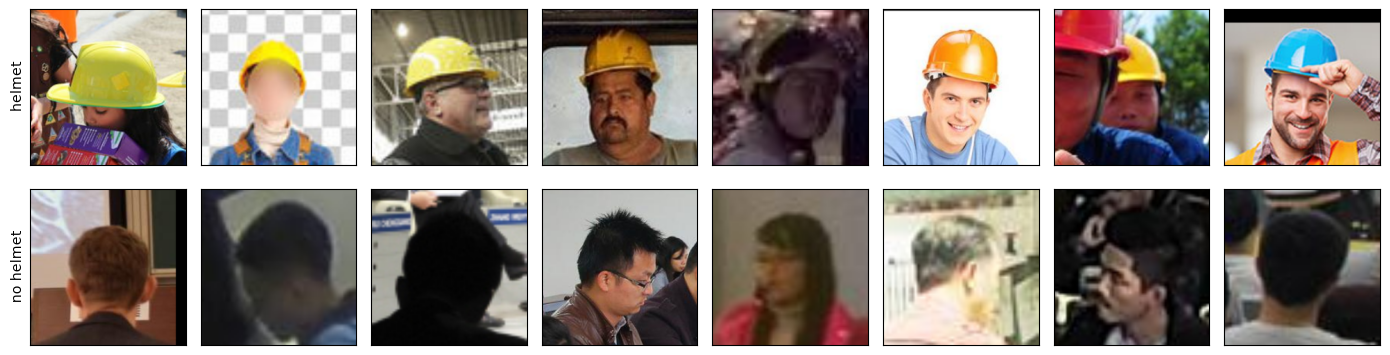

In [5]:
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for row, (label, title) in enumerate([(1, "helmet"), (0, "no helmet")]):
    idx = list(np.random.default_rng(0).choice(np.where(used.y == label)[0], 8, replace=False))
    for ax, im in zip(axes[row], crops(idx)):
        ax.imshow(im); ax.set_xticks([]); ax.set_yticks([])
    axes[row, 0].set_ylabel(title)
plt.tight_layout(); plt.savefig(OUTPUTS / "05_shwd_head_crops.png", dpi=120); plt.show()

## 4. One feature vector of 2,048 numbers per crop (frozen ResNet50)

ResNet50 is not trained, so each crop goes through it **only once** and we save its vector. Notebook 06 trains on these vectors in seconds.

- `preprocess_input`: RGB → BGR and subtract the ImageNet mean (103.939, 116.779, 123.68).
- ResNet50 without its last layer → 7 × 7 × 2,048 map → mean of each channel (`pooling="avg"`) → vector of 2,048.
- We process 1,024 crops at a time: keeping all ~33,000 crops in memory would take ~5 GB.
- Vectors are saved as float16 to use half the disk space. The lost precision does not matter for a dense layer.

In [6]:
extractor = ResNet50(include_top=False, pooling="avg", weights="imagenet", input_shape=(SIZE, SIZE, 3))
# "used" is sorted by photo, so each batch opens few photos
F = np.concatenate([extractor.predict(preprocess_input(crops(list(range(i, min(i + 1024, len(used))))).astype("float32")),
                                      batch_size=64, verbose=0)
                    for i in range(0, len(used), 1024)])
np.save(FEATURES / "shwd_head_vectors.npy", F.astype("float16"))
used.to_csv(FEATURES / "shwd_heads.csv", index=False)
print(F.shape, f"{(FEATURES / 'shwd_head_vectors.npy').stat().st_size / 1e6:.0f} MB")

(33393, 2048) 137 MB
